# VI and MCMC with iTARFlow

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


METIS's [normalising flow surrogate](https://ojwatson.github.io/metis/models/normalising-flow.html) has an
exactly evaluable density. This lets us substitute the fitted surrogate into
inference methods such as variational inference (VI) and Markov chain Monte
Carlo (MCMC).

Conceptually, the simulator has a likelihood $p^*(y\mid\theta)$ that we cannot
easily evaluate. We fit a surrogate density $\hat p(y\mid\theta)$ and hope it
approximates the features of that likelihood needed for inference. An exact
calculation of $\hat p$ does not make it the exact simulator likelihood.

## Setup

We continue with the same [SIRDS model](https://ojwatson.github.io/metis/basics/sirds-example.html), its four
count trajectories, and the full original simulation bank: 1,000 parameter
settings, five realisations each, and days 1–200. The following cells run
when the documentation is built, including VI and MCMC. They illustrate
inference under a fitted surrogate; they do not validate it as a SIRDS likelihood.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)
torch.manual_seed(42)

## Train the surrogate

As in the normalising-flow tutorial, we fit a small iTARFlow model on the SIRDS
training groups and select its weights using the validation groups. Here we
use 10,000 optimiser updates for the likelihood example; this takes several
minutes on a CPU.
Setting `patch_size=5` groups five adjacent days into each internal token to
make CPU training faster; all 200 daily values are still modelled and returned.

In [2]:
nf = Surrogate(
    "itarflow",
    model_options={
        "channels": 32, "num_layers": 1, "num_blocks": 2, "num_heads": 2,
        "patch_size": 5,
    },
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=10000, batch_size=64, eval_every=100, seed=42),
)
nf.save("sirds-likelihood.pt")

PosixPath('sirds-likelihood.pt')

## Load the trained surrogate

The saved model includes its input and output names, time grid and fitted
scalers. Loading it does not require the training data or a reconstruction of
its preprocessing:

In [3]:
nf = Surrogate.load("sirds-likelihood.pt")
print("Inputs:", nf.input_names)
print("Outputs:", nf.output_names)

Inputs: ('I_0', 'beta', 'gamma', 'omega', 'mu')
Outputs: ('S_t', 'I_t', 'R_t', 'D_t')


## Preparing an observation

Use one trajectory from a held-out SIRDS parameter group as our observation.
For this illustration, select a group inside each training-input range and
the prior bounds used below. Its generating parameters are known, so we can
compare them with a likelihood slice later. For a scientific application this would instead be the observed
data whose likelihood is being evaluated.

In [4]:
prior_bounds = {
    "I_0": (0.01, 0.1), "beta": (0.2, 0.8),
    "gamma": (0.05, 0.3), "omega": (0.005, 0.05),
}
in_range = np.all(
    (split.test.inputs >= split.train.inputs.min(axis=0))
    & (split.test.inputs <= split.train.inputs.max(axis=0)), axis=1,
)
for name, (lower, upper) in prior_bounds.items():
    values = split.test.inputs[:, bank.input_names.index(name)]
    in_range &= (values >= lower) & (values <= upper)
observation_index = np.flatnonzero(in_range)[0]
true_inputs = split.test.inputs[observation_index:observation_index + 1].copy()
y_obs = split.test.outputs[observation_index:observation_index + 1].copy()
same_setting = np.all(split.test.inputs == true_inputs[0], axis=1)
replicates = split.test.outputs[same_setting]
draws = nf.sample(true_inputs, n_samples=100, seed=13)[0]
pd.DataFrame(true_inputs, columns=bank.input_names)

,I_0,beta,gamma,omega,mu
0,0.011321,0.208096,0.187154,0.029451,0.039343


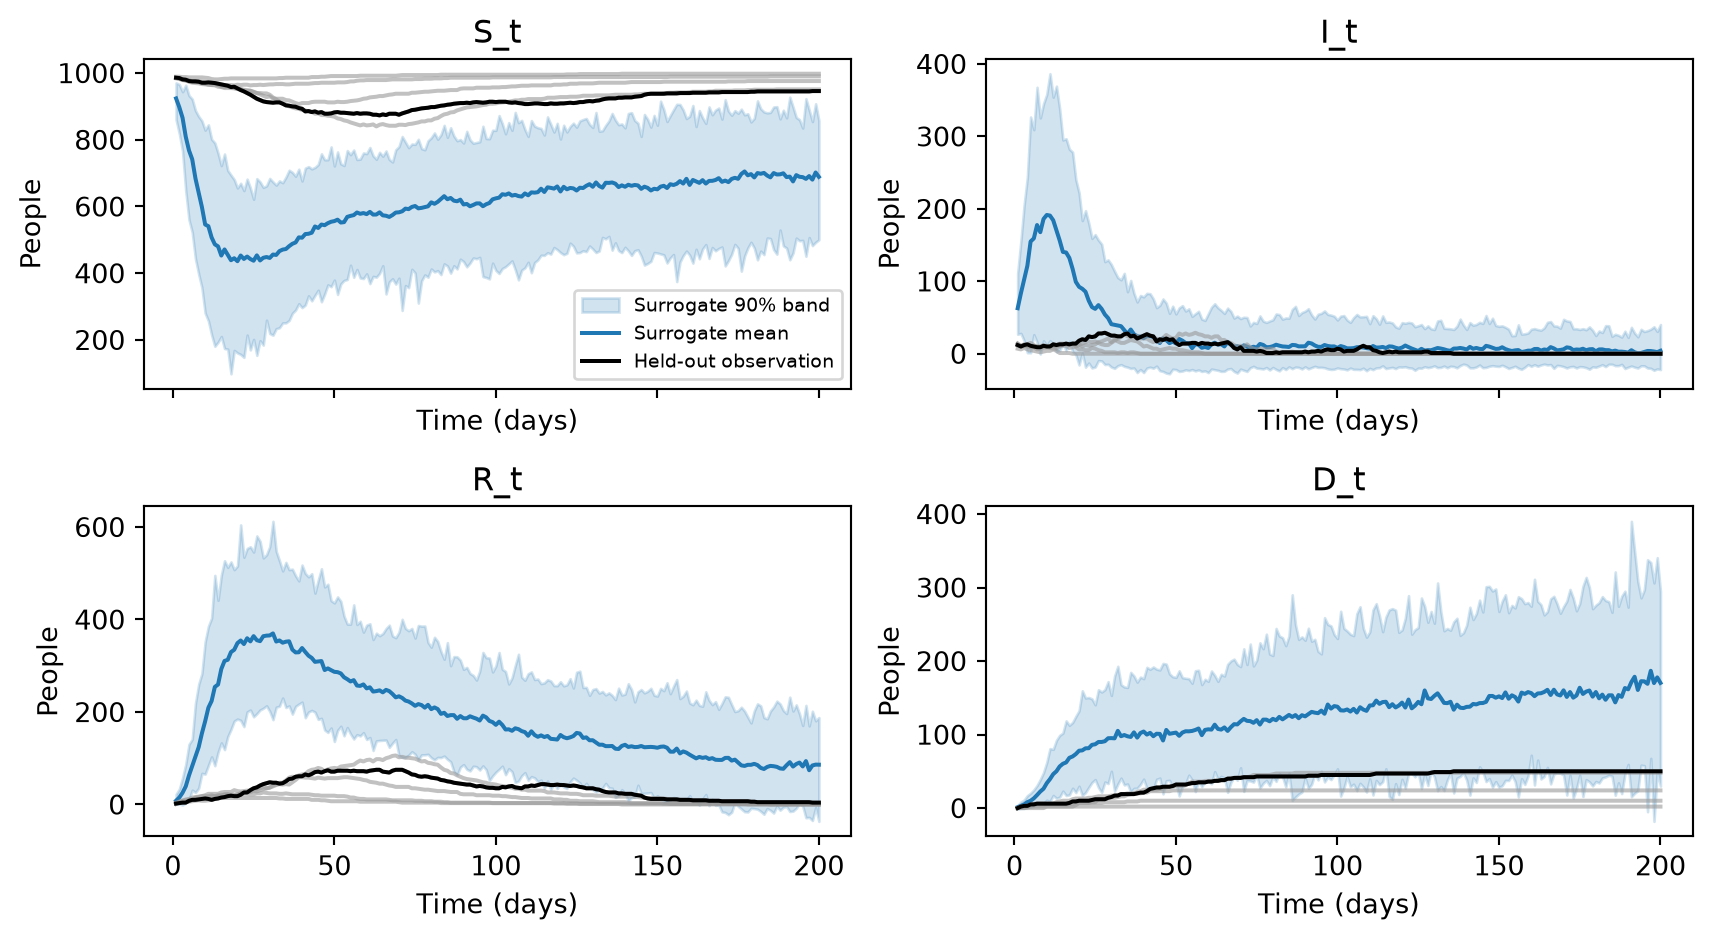

In [5]:
#| code-fold: true
#| code-summary: "Compare surrogate samples with held-out SIRDS trajectories"
#| fig-cap: "iTARFlow fitted to the bundled SIRDS training split: surrogate samples at one held-out parameter setting, compared with its five SIRDS realisations. Shading is the pointwise 5th–95th percentile of 100 surrogate draws, not a posterior interval."
low, high = np.quantile(draws, [0.05, 0.95], axis=0)
fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True)
for j, ax in enumerate(axes.flat):
    ax.fill_between(bank.times, low[:, j], high[:, j], alpha=0.2,
                    color="C0", label="Surrogate 90% band")
    ax.plot(bank.times, draws.mean(axis=0)[:, j], color="C0", label="Surrogate mean")
    ax.plot(bank.times, replicates[:, :, j].T, color="0.6", alpha=0.6)
    ax.plot(bank.times, y_obs[0, :, j], color="black", label="Held-out observation")
    ax.set(title=bank.output_names[j], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

*iTARFlow fitted to the bundled SIRDS training split: surrogate samples at one held-out parameter setting, compared with its five SIRDS realisations. Shading is the pointwise 5th–95th percentile of 100 surrogate draws, not a posterior interval.*

At this setting, the fitted surrogate overestimates the outbreak and generates
some negative counts. More training has not made this a reliable SIRDS
likelihood. The inference below shows how to connect the components and inspect
the resulting target; it should not be interpreted as validated parameter recovery.

## Evaluating the likelihood

`log_prob` accepts inputs and trajectories in their original units. To inspect
its dependence on transmission rate, vary $\beta$ while holding the other four
inputs at their generating values:

In [6]:
beta_index = bank.input_names.index("beta")
beta = np.linspace(split.train.inputs[:, beta_index].min(),
                   split.train.inputs[:, beta_index].max(), 100)
candidates = np.repeat(true_inputs, len(beta), axis=0)
candidates[:, beta_index] = beta
log_density = nf.log_prob(candidates, np.repeat(y_obs, len(beta), axis=0))

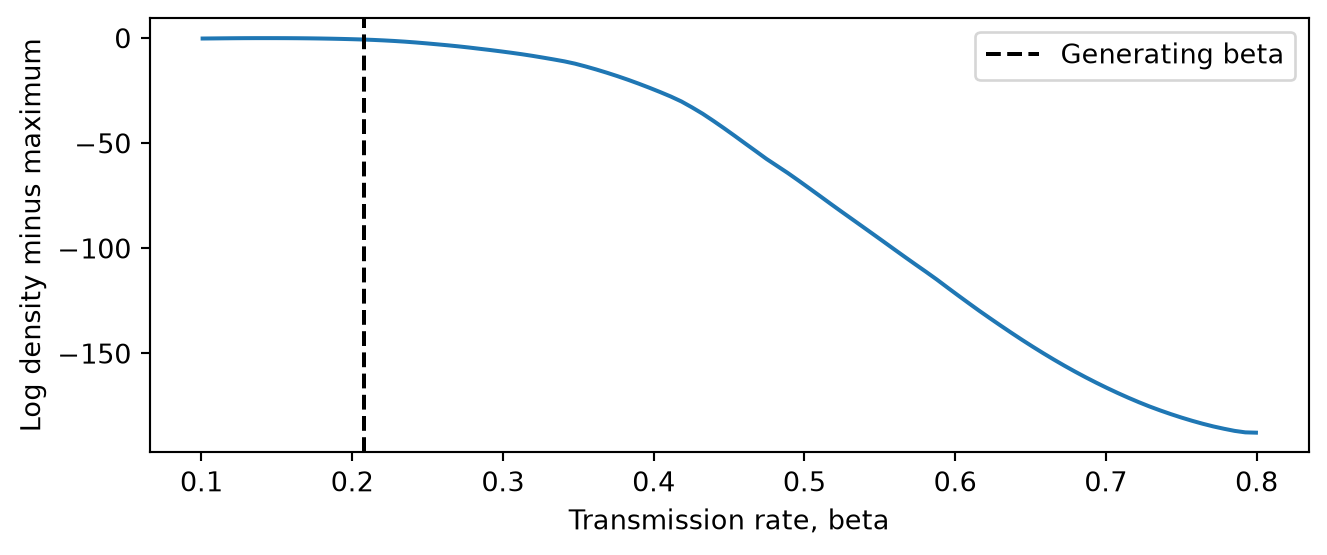

In [7]:
#| fig-cap: "iTARFlow fitted to the bundled SIRDS training split: conditional log-density slice for one held-out SIRDS trajectory, with I₀, γ, ω and μ fixed to their generating values. The curve is shifted to its maximum; it is not a marginal likelihood or posterior."
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(beta, log_density - log_density.max())
ax.axvline(true_inputs[0, beta_index], color="black", linestyle="--",
           label="Generating beta")
ax.set(xlabel="Transmission rate, beta", ylabel="Log density minus maximum")
ax.legend()
fig.tight_layout()
plt.show()

*iTARFlow fitted to the bundled SIRDS training split: conditional log-density slice for one held-out SIRDS trajectory, with I₀, γ, ω and μ fixed to their generating values. The curve is shifted to its maximum; it is not a marginal likelihood or posterior.*

For gradient-based methods, `log_prob_tensor` keeps the calculation connected
to PyTorch's automatic differentiation. Scaling and its density correction
are handled inside the package:

In [8]:
theta = torch.tensor(true_inputs, requires_grad=True)
observed = torch.tensor(y_obs)
log_likelihood = nf.log_prob_tensor(theta, observed)
gradient, = torch.autograd.grad(log_likelihood.sum(), theta)
print("Log density:", float(log_likelihood.detach()[0]))
print("Gradient in original input units:")
for name, value in zip(bank.input_names, gradient[0].tolist()):
    print(f"  {name}: {value:.3f}")

Log density: -3184.7940092137424
Gradient in original input units:
  I_0: -72.947
  beta: -24.720
  gamma: 8.750
  omega: -21.817
  mu: -31.072


SIRDS has integer counts and a fixed population total. A continuous flow does
not enforce this support, and its density is not a discrete trajectory
probability. Before interpreting a posterior, validate an appropriate
likelihood or observation model, simulation coverage and inference diagnostics.
No observation-error model is added in this tutorial.

## Choosing the prior

We infer the
initial infected fraction $I_0$, transmission $\beta$, recovery $\gamma$ and
waning $\omega$, holding mortality $\mu$ known. The example uniform priors are:

$$
\begin{aligned}
I_0 &\sim \mathcal U(0.01, 0.1), &
\beta &\sim \mathcal U(0.2, 0.8),\\
\gamma &\sim \mathcal U(0.05, 0.3), &
\omega &\sim \mathcal U(0.005, 0.05).
\end{aligned}
$$

These are choices for the example, not priors selected by METIS. They must be
scientifically justified and covered by a validated simulation bank before
use. The training objective and single likelihood slice above are not that
validation.
The bounds reach slightly beyond the extrema of this finite training sample,
so METIS warns when inference proposes inputs there. Both methods keep these
same priors; extrapolation remains a limitation of the demonstration.

## The inference problem

Given observation $y_{\mathrm{obs}}$, prior $p(\theta)$ and the fitted surrogate,
the unnormalised approximate posterior is

$$
p(\theta\mid y_{\mathrm{obs}})\propto
\hat p(y_{\mathrm{obs}}\mid\theta)\,p(\theta).
$$

VI fits a tractable distribution to this target; MCMC generates samples from
it. Both use the same held-out SIRDS observation and public likelihood interface.
The inference results below are conditional on this fitted continuous surrogate,
its point-estimated neural weights, the chosen priors and the known mortality
rate. They are not validated estimates under the exact SIRDS simulator.

In [9]:
import torch.distributions as dist
from torch import nn

parameter_names = list(prior_bounds)
lo = torch.tensor([bounds[0] for bounds in prior_bounds.values()])
hi = torch.tensor([bounds[1] for bounds in prior_bounds.values()])
known_mu = float(true_inputs[0, bank.input_names.index("mu")])

# Freeze fitted neural weights while preserving gradients through the inputs.
nf.model.requires_grad_(False)

def make_inputs(theta_samples):
    values = dict(zip(parameter_names, theta_samples.unbind(dim=1)))
    values["mu"] = torch.full_like(theta_samples[:, 0], known_mu)
    return torch.stack([values[name] for name in nf.input_names], dim=1)

def compute_log_likelihood(theta_samples):
    return nf.log_prob_tensor(
        make_inputs(theta_samples),
        observed.expand(len(theta_samples), -1, -1),
    )

## Variational inference

Introduce a parametrised distribution $q_\phi(\theta)$ and maximise the evidence
lower bound (ELBO):

$$
\max_\phi\;\mathbb E_{q_\phi}\left[
\log\hat p(y_{\mathrm{obs}}\mid\theta)+\log p(\theta)-\log q_\phi(\theta)
\right].
$$

This is equivalent to minimising the reverse KL divergence from $q_\phi$ to
the approximate posterior. As in the original workflow, use a multivariate
Gaussian transformed into the parameter bounds. We use 1,500 Adam updates,
32 Monte Carlo draws per update and learning rate 0.02:

In [10]:
import torch.nn.functional as F

torch.manual_seed(42)
n_params = len(parameter_names)
q_mu = nn.Parameter(torch.zeros(n_params))
q_L_flat = nn.Parameter(torch.zeros(n_params * (n_params + 1) // 2))

def build_q():
    L = torch.zeros(n_params, n_params)
    row, column = torch.tril_indices(n_params, n_params)
    L[row, column] = q_L_flat
    diagonal = torch.arange(n_params)
    L[diagonal, diagonal] = F.softplus(L[diagonal, diagonal])
    base = dist.MultivariateNormal(q_mu, scale_tril=L)
    return dist.TransformedDistribution(base, [
        dist.SigmoidTransform(), dist.AffineTransform(lo, hi - lo),
    ])

optimizer = torch.optim.Adam([q_mu, q_L_flat], lr=0.02)
elbo_history = []
for step in range(1500):
    optimizer.zero_grad()
    q = build_q()
    theta_samples = q.rsample((32,))
    log_prior = -torch.log(hi - lo).sum()
    elbo = (compute_log_likelihood(theta_samples)
            + log_prior - q.log_prob(theta_samples)).mean()
    (-elbo).backward()
    optimizer.step()
    elbo_history.append(float(elbo.detach()))

with torch.no_grad():
    vi_samples = build_q().sample((5000,)).numpy()

/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(


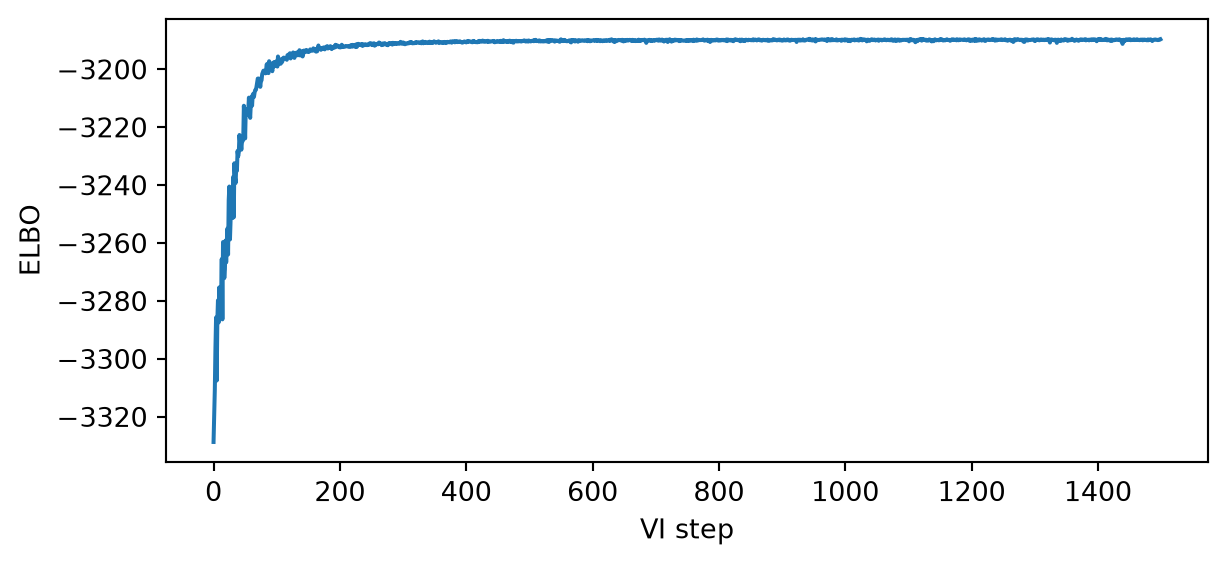

In [11]:
#| fig-cap: "VI ELBO for the iTARFlow surrogate fitted on the full original SIRDS training partition, conditional on one held-out trajectory and the stated priors. This is an optimisation diagnostic, not a likelihood-validation result."
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(elbo_history)
ax.set(xlabel="VI step", ylabel="ELBO")
plt.show()

*VI ELBO for the iTARFlow surrogate fitted on the full original SIRDS training partition, conditional on one held-out trajectory and the stated priors. This is an optimisation diagnostic, not a likelihood-validation result.*

Check convergence from different initialisations. An improving ELBO alone does
not show that the approximation represents every posterior mode or correlation.

## MCMC

Pyro's No-U-Turn Sampler (NUTS) samples the same surrogate-based target. Pyro
is included in METIS's tutorial dependencies and in the Colab setup. If you
installed METIS without those extras, add it with `uv add pyro-ppl`.

Each `pyro.sample` declares a prior, and `pyro.factor` contributes the surrogate
log likelihood. Pyro handles the transforms for bounded parameters.

In [12]:
import pyro
import pyro.distributions as pyro_dist
from pyro.infer import MCMC, NUTS

pyro.set_rng_seed(42)

def posterior_model():
    theta = torch.stack([
        pyro.sample(name, pyro_dist.Uniform(lo[i], hi[i]))
        for i, name in enumerate(parameter_names)
    ])
    pyro.factor("surrogate_likelihood", compute_log_likelihood(theta[None])[0])

kernel = NUTS(posterior_model, full_mass=True, target_accept_prob=0.8)
mcmc = MCMC(kernel, warmup_steps=500, num_samples=1000, num_chains=1, disable_progbar=True)
mcmc.run()
mcmc.summary(prob=0.95)
diagnostics = mcmc.diagnostics()
print("Divergences:", sum(len(indices) for indices in diagnostics["divergences"].values()))
print("Acceptance rate:", diagnostics["acceptance rate"])
mcmc_draws = mcmc.get_samples()
mcmc_samples = torch.stack([mcmc_draws[name] for name in parameter_names], dim=1)

/home/runner/work/metis/metis/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['I_0', 'gamma']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(
/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['gamma']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(
/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['I_0', 'gamma', 'omega']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(
/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(
/tmp/ipyk

/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['omega']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(


/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['I_0', 'beta', 'gamma', 'omega']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(


/tmp/ipykernel_2994/3787405875.py:18: UserWarning: Inputs outside the training ranges for ['gamma', 'omega']; predictions extrapolate and are not clipped.
  return nf.log_prob_tensor(



                mean       std    median      2.5%     97.5%     n_eff     r_hat
       I_0      0.02      0.01      0.02      0.01      0.04    715.34      1.00
      beta      0.23      0.02      0.22      0.20      0.28    594.13      1.00
     gamma      0.25      0.04      0.25      0.18      0.30    417.33      1.00
     omega      0.03      0.01      0.03      0.01      0.05    410.92      1.00

Number of divergences: 0
Divergences: 0
Acceptance rate: {'chain 0': 0.995}


Warmup adapts the sampler and is discarded. We run one chain with 500 warmup
steps and retain 1,000 draws. The summary shows effective sample sizes and
split-chain R-hat; a one-chain result cannot establish agreement across
independently initialised chains. Inspect these diagnostics and the traces
before interpreting posterior features.

### MCMC trace plots

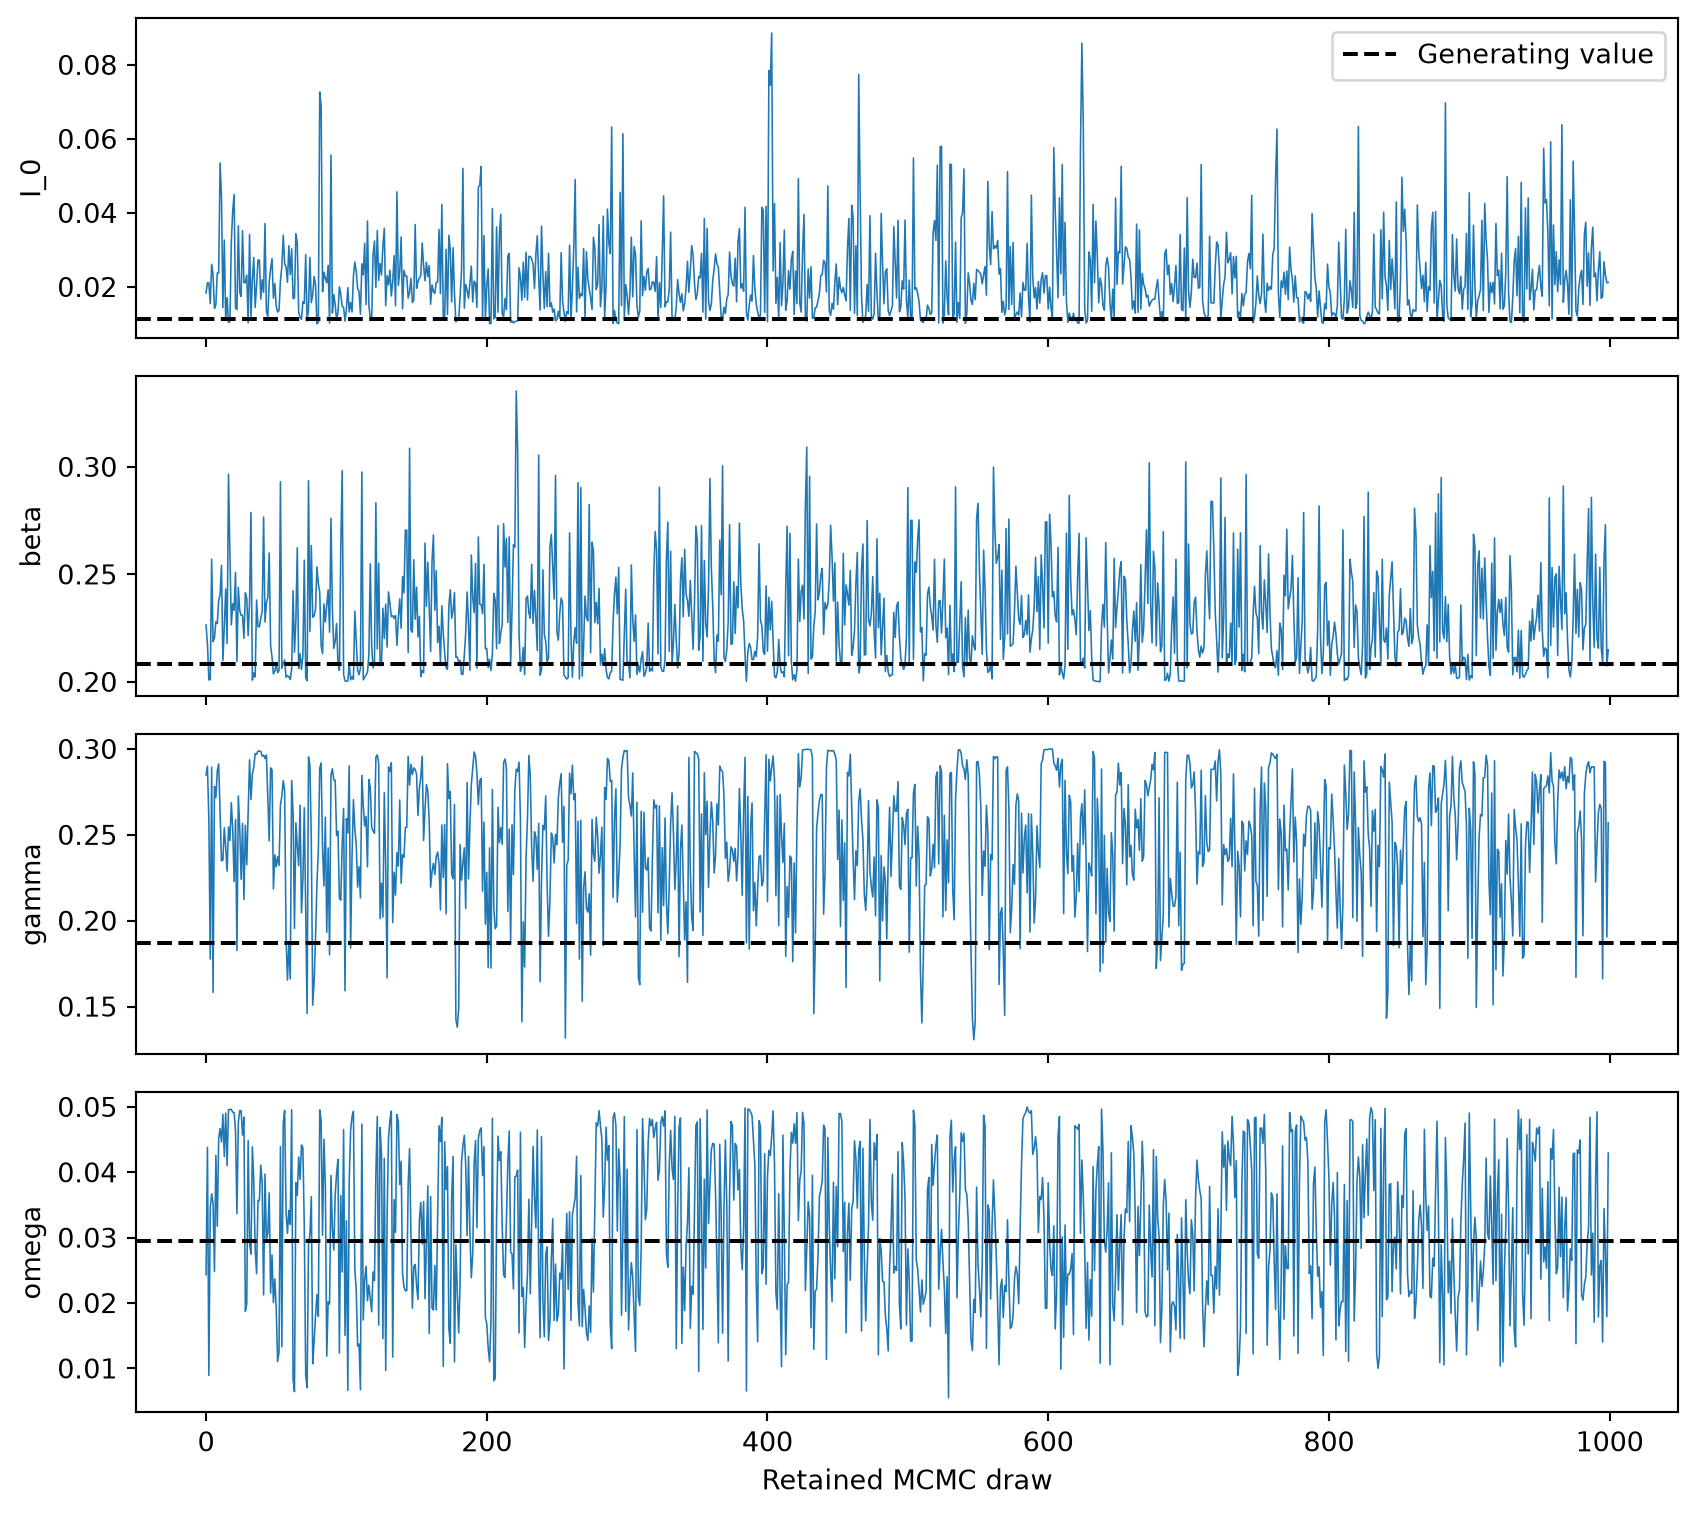

In [13]:
#| fig-cap: "One-chain NUTS traces for the iTARFlow SIRDS surrogate posterior, conditional on the selected held-out trajectory and stated priors. Dashed lines show the generating parameters; warmup is excluded."
fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
for j, (name, ax) in enumerate(zip(parameter_names, axes)):
    ax.plot(mcmc_samples[:, j].numpy(), linewidth=0.6)
    generating = true_inputs[0, bank.input_names.index(name)]
    ax.axhline(generating, color="black", linestyle="--", label="Generating value")
    ax.set(ylabel=name)
axes[0].legend()
axes[-1].set_xlabel("Retained MCMC draw")
fig.tight_layout()
plt.show()

*One-chain NUTS traces for the iTARFlow SIRDS surrogate posterior, conditional on the selected held-out trajectory and stated priors. Dashed lines show the generating parameters; warmup is excluded.*

### Comparing VI and MCMC

Compare marginal distributions on the diagonal and joint parameter
relationships below it. Agreement between the methods does not establish that
the surrogate likelihood itself is accurate. Differences can reflect a
restricted variational family, incomplete optimisation or inadequate MCMC mixing.

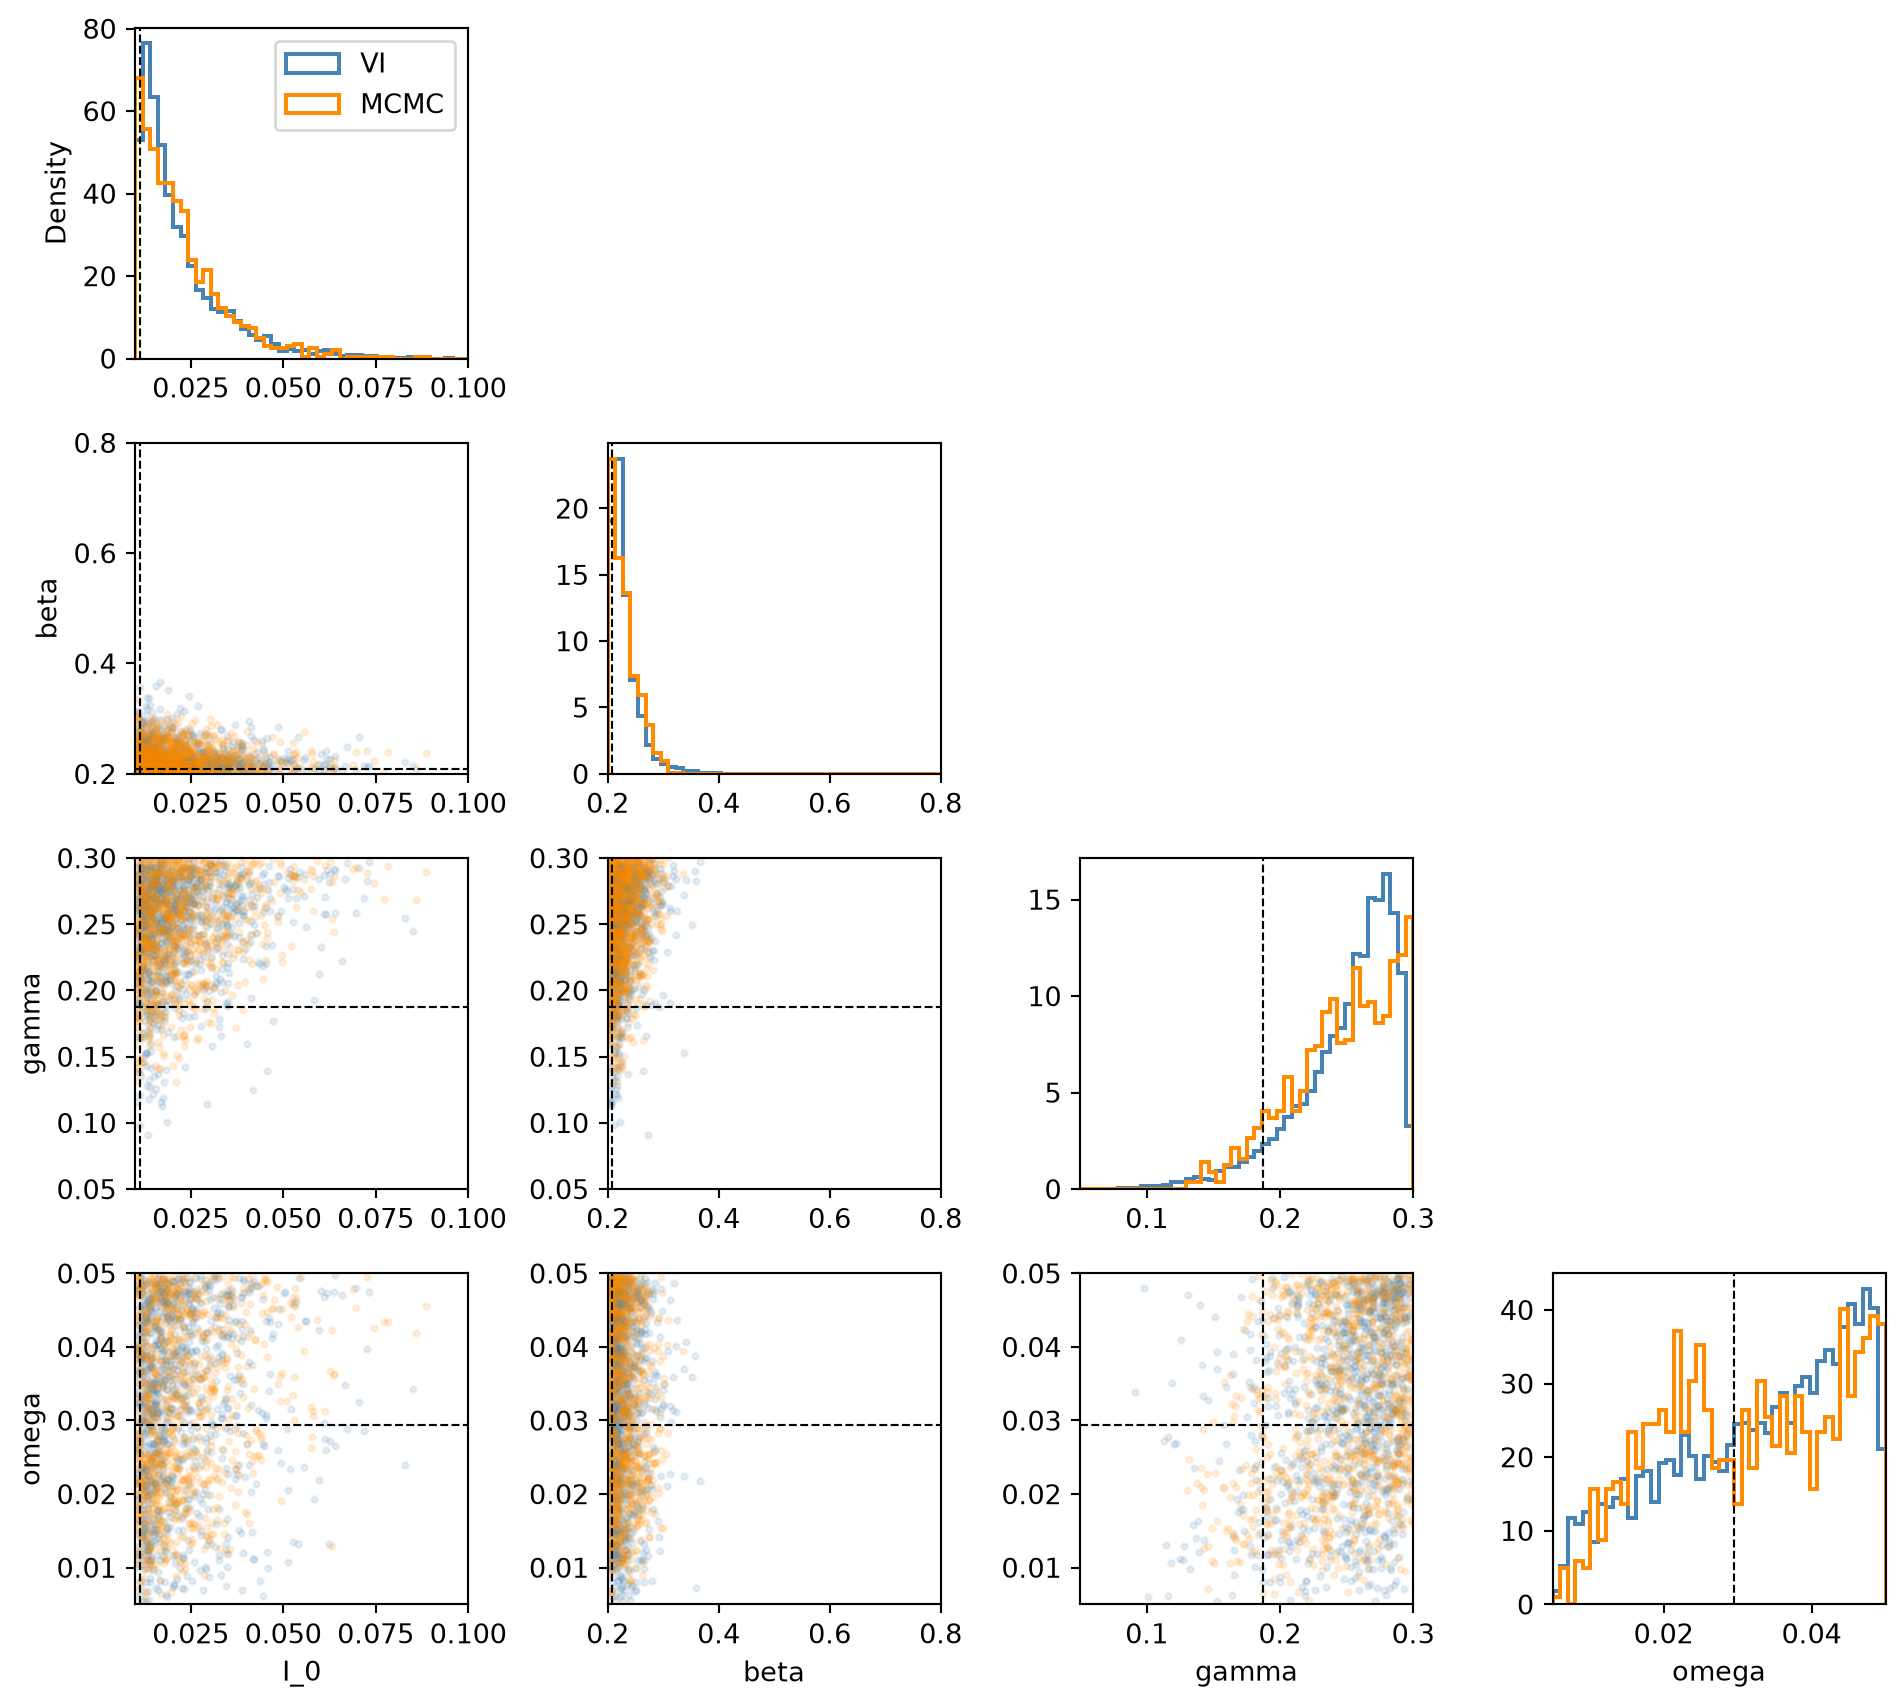

In [14]:
#| code-fold: true
#| code-summary: "Plot marginal and joint VI/MCMC draws"
#| fig-cap: "VI and one-chain NUTS approximations to the same iTARFlow SIRDS surrogate posterior, using the full original training bank and one held-out observation. Dashed lines indicate its generating parameters. These distributions exclude uncertainty in fitted neural weights."
mcmc_array = mcmc_samples.numpy()
comparison_samples = [("VI", vi_samples, "steelblue"),
                      ("MCMC", mcmc_array, "darkorange")]
fig, axes = plt.subplots(4, 4, figsize=(10, 9))
for i, row in enumerate(axes):
    for j, ax in enumerate(row):
        if j > i:
            ax.axis("off")
            continue
        if i == j:
            bins = np.linspace(*prior_bounds[parameter_names[i]], 45)
            for label, samples, colour in comparison_samples:
                ax.hist(samples[:, i], bins=bins, density=True,
                        histtype="step", linewidth=1.5, color=colour, label=label)
        else:
            for label, samples, colour in comparison_samples:
                ax.scatter(samples[:1000, j], samples[:1000, i],
                           s=5, alpha=0.12, color=colour, rasterized=True)
            ax.axhline(true_inputs[0, bank.input_names.index(parameter_names[i])],
                       color="black", linestyle="--", linewidth=0.8)
            ax.set_ylim(prior_bounds[parameter_names[i]])
        ax.axvline(true_inputs[0, bank.input_names.index(parameter_names[j])],
                   color="black", linestyle="--", linewidth=0.8)
        ax.set_xlim(prior_bounds[parameter_names[j]])
        if j == 0:
            ax.set_ylabel("Density" if i == 0 else parameter_names[i])
        if i == 3:
            ax.set_xlabel(parameter_names[j])
axes[0, 0].legend()
fig.tight_layout()
plt.show()

*VI and one-chain NUTS approximations to the same iTARFlow SIRDS surrogate posterior, using the full original training bank and one held-out observation. Dashed lines indicate its generating parameters. These distributions exclude uncertainty in fitted neural weights.*

The central 95% intervals below describe parameter uncertainty under each
approximation to this surrogate posterior. They are not confidence intervals
for the true simulator parameters.

In [15]:
#| tbl-cap: "VI and one-chain NUTS parameter summaries for the full-bank iTARFlow SIRDS surrogate, conditional on the same held-out trajectory, stated priors and fixed mortality rate."
summaries = []
for label, samples, _ in comparison_samples:
    for j, name in enumerate(parameter_names):
        lower, upper = np.quantile(samples[:, j], [0.025, 0.975])
        summaries.append({
            "Method": label, "Parameter": name, "Mean": samples[:, j].mean(),
            "2.5%": lower, "97.5%": upper,
            "Generating value": true_inputs[0, bank.input_names.index(name)],
        })
pd.DataFrame(summaries).round(4)

,Method,Parameter,Mean,2.5%,97.5%,Generating value
0,VI,I_0,0.0222,0.0109,0.0561,0.0113
1,VI,beta,0.2306,0.2046,0.3015,0.2081
2,VI,gamma,0.2504,0.1563,0.2934,0.1872
3,VI,omega,0.0327,0.0086,0.0489,0.0295
4,MCMC,I_0,0.0225,0.0104,0.0531,0.0113
5,MCMC,beta,0.2296,0.2008,0.2903,0.2081
6,MCMC,gamma,0.2471,0.1628,0.2987,0.1872
7,MCMC,omega,0.0316,0.0109,0.0493,0.0295


### Posterior predictive checks

Generate surrogate trajectories at VI and MCMC parameter draws and compare
with the observed SIRDS trajectory. We do not clip negative counts or enforce
conservation after sampling: those discrepancies help reveal a poor surrogate.

/home/runner/work/metis/metis/src/metis/surrogate.py:737: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


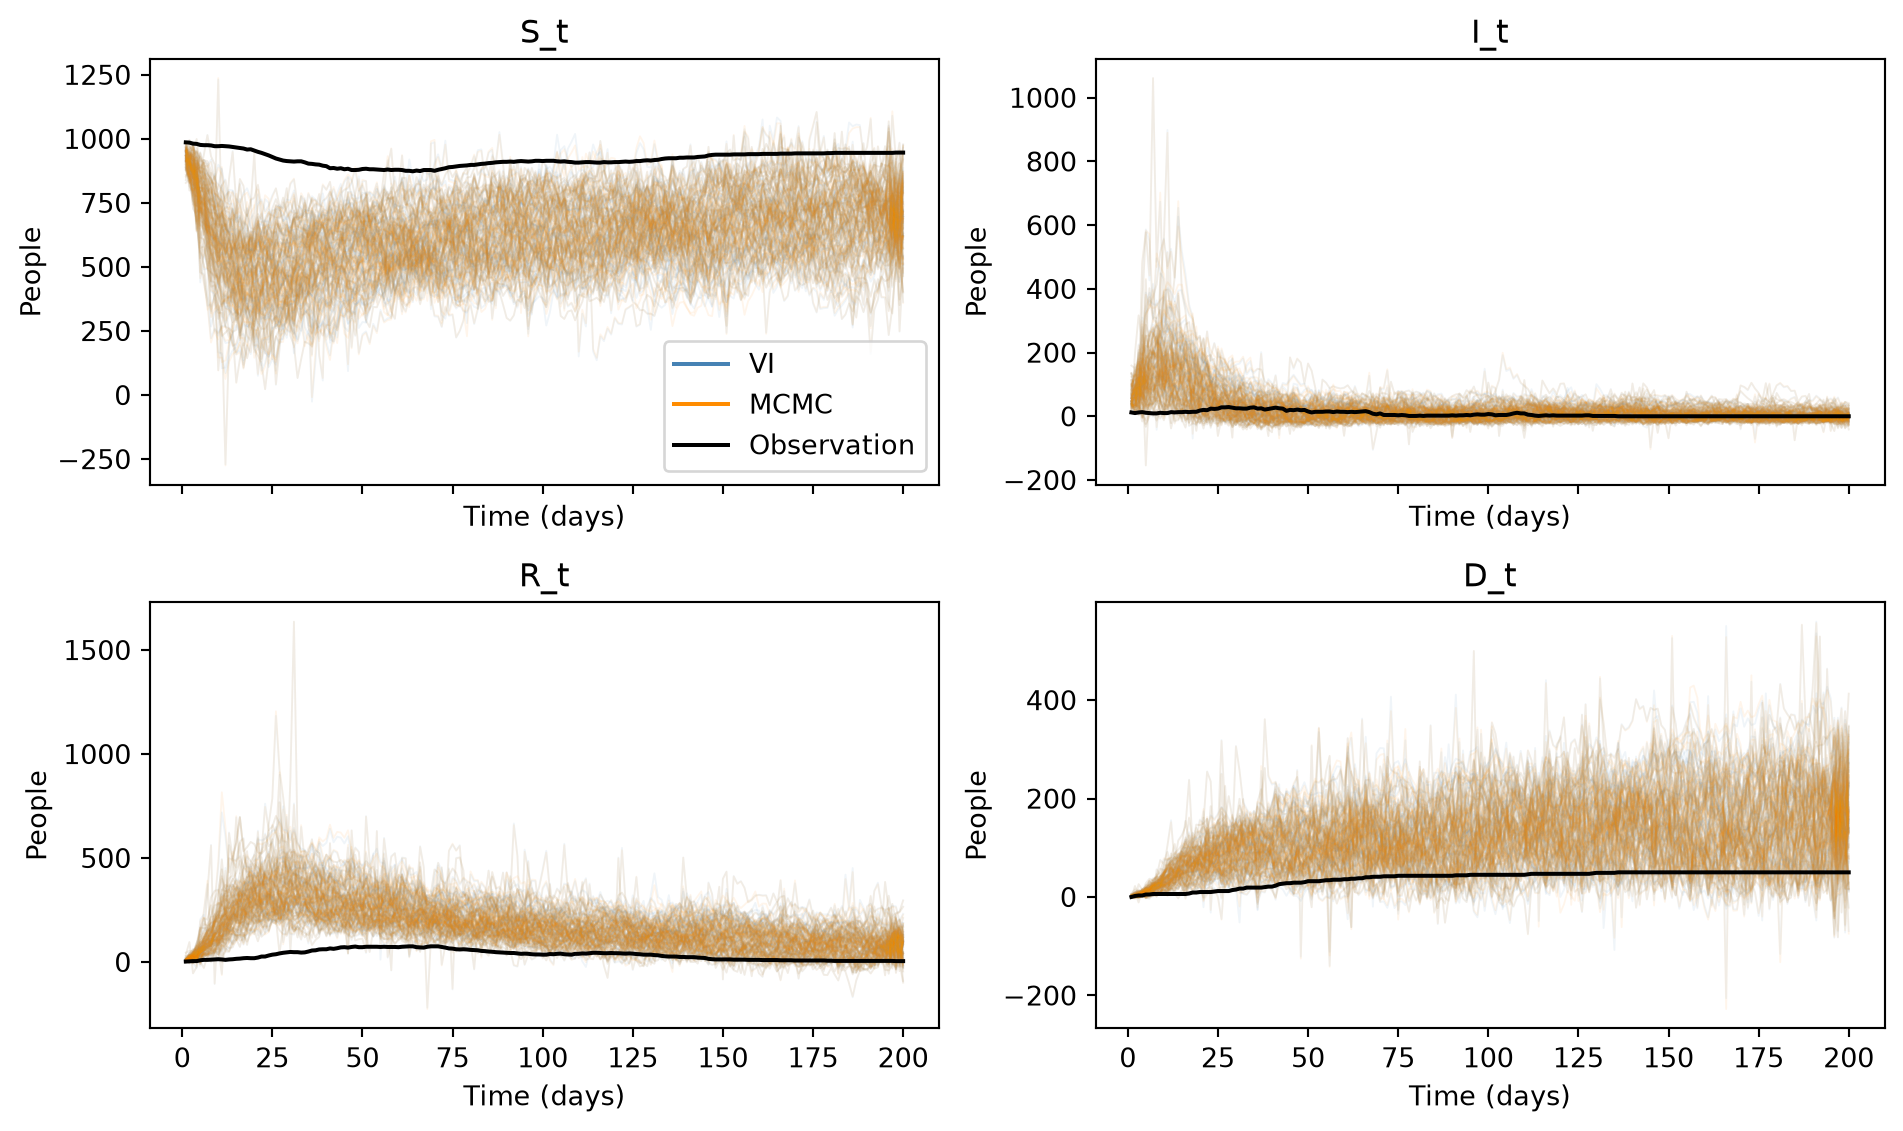

In [16]:
#| code-fold: true
#| code-summary: "Draw trajectories under VI and MCMC parameter samples"
#| fig-cap: "Posterior predictive trajectories under the fitted iTARFlow SIRDS surrogate for VI (blue) and one-chain NUTS (orange), conditional on the selected held-out observation (black). Each method supplies 100 parameter draws and one surrogate trajectory per draw; no clipping or conservation correction is applied."
posterior_predictive = {}
for label, samples, colour in comparison_samples:
    selected = torch.as_tensor(samples[:100], dtype=torch.float32)
    posterior_inputs = make_inputs(selected).detach().numpy()
    posterior_predictive[label] = nf.sample(
        posterior_inputs, n_samples=1, seed=42
    )[:, 0]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for j, ax in enumerate(axes.flat):
    for label, _, colour in comparison_samples:
        ax.plot(bank.times, posterior_predictive[label][:, :, j].T,
                color=colour, alpha=0.08, linewidth=0.7)
        ax.plot([], [], color=colour, label=label)
    ax.plot(bank.times, y_obs[0, :, j], color="black", label="Observation")
    ax.set(title=bank.output_names[j], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend()
fig.tight_layout()
plt.show()

*Posterior predictive trajectories under the fitted iTARFlow SIRDS surrogate for VI (blue) and one-chain NUTS (orange), conditional on the selected held-out observation (black). Each method supplies 100 parameter draws and one surrogate trajectory per draw; no clipping or conservation correction is applied.*

These posterior draws describe parameter uncertainty under the chosen prior
and fitted surrogate. The predictive draws also include the variability
learned by that surrogate, but neither includes uncertainty in its neural
weights. A further validation step is to run the actual SIRDS simulator at
posterior draws and compare its trajectories with the observation.